# Entropy Calculation on Simulated Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import entropy
import EntropyHub as EH

## 1. Shannon Entropy

$$
H(X)=-\sum_{i=1}^{n}p_i\log(p_i)
$$

$p_i$ is the probability of the $i$-th outcome (the $i$-th histogram bin). Shannon entropy measures how spread out / uncertain the **value distribution** is, ignoring temporal order.

### 1.1 Generate simulated probability distributions

In [2]:
# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Parameters
mean = 100
n = 1000

# Simulate normal distributions
dist_1 = rng.normal(loc=mean, scale=5, size=n)
dist_2 = rng.normal(loc=mean, scale=10, size=n)
dist_3 = rng.normal(loc=mean, scale=20, size=n)

distributions = {
    "dist_1": dist_1,
    "dist_2": dist_2,
    "dist_3": dist_3
}


### 1.2 Visualize the data

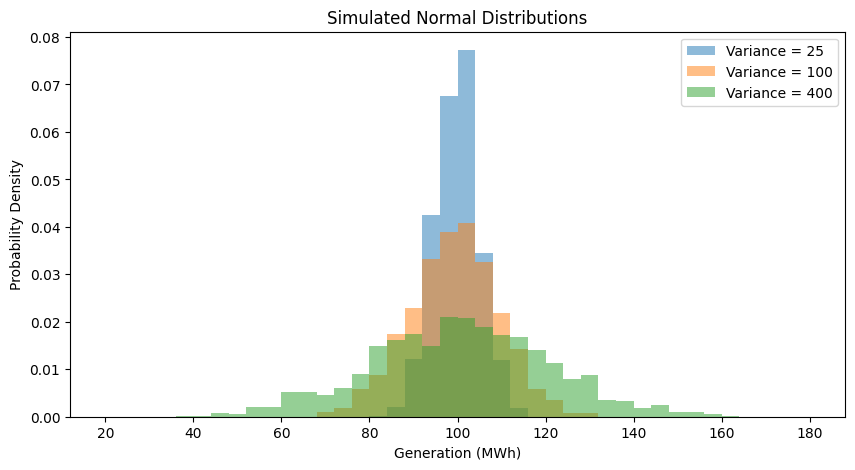

In [3]:
plt.figure(figsize=(10, 5))

bins = np.linspace(20, 180, 41)

plt.hist(dist_1, bins=bins, alpha=0.5,
         label="Variance = 25", density=True)
plt.hist(dist_2, bins=bins, alpha=0.5,
         label="Variance = 100", density=True)
plt.hist(dist_3, bins=bins, alpha=0.5,
         label="Variance = 400", density=True)

plt.xlabel("Generation (MWh)")
plt.ylabel("Probability Density")
plt.title("Simulated Normal Distributions")
plt.legend()
plt.show()

### 1.3 Calculate Shannon Entropy

In [4]:
results = []

for name, data in distributions.items():
    counts, _ = np.histogram(data, bins=bins) # Bin the data into counts
    p = counts / counts.sum() # Convert counts to probabilities p_i
    H = entropy(p, base=2) # H = -Σ p_i log2(p_i)

    results.append({
        "Distribution": name,
        "Variance": round(data.var()),
        "Shannon Entropy": round(H, 4)
    })

results_df = pd.DataFrame(results)
results_df


,Distribution,Variance,Shannon Entropy
0,dist_1,24,2.4017
1,dist_2,103,3.3799
2,dist_3,413,4.3730


Text(0.5, 1.0, 'Shannon Entropy of Simulated Normal Distributions')

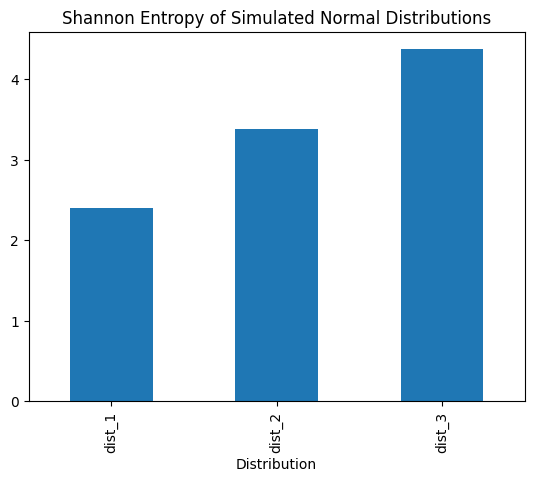

In [5]:
results_df.plot(x="Distribution", y="Shannon Entropy", kind="bar", legend=False)
plt.title("Shannon Entropy of Simulated Normal Distributions")

### 1.4 Finding
Higher variance → Higher histogram-based Shannon entropy.

Shannon entropy measures the uncertainty of a probability distribution without requiring knowledge of the chronological order in which the outcomes occur.

## 2. Sample Entropy

$$
\operatorname{SampEn}(m,r)=-\ln\left(\frac{A}{B}\right)
$$

$B$ is the number of template matches of length $m$ (within tolerance $r$). 
$A$ is the number of those matches that still match when extended to length $m+1$ (using a consistent counting convention and excluding self-matches). 

Sample entropy measures the **irregularity / unpredictability** of a time series: lower values mean more repeating patterns.

### 2.1 Generate simulated time series (by AR process)

Simulate AR(1) time series in two experiments:

$$
V_t = \alpha + \gamma V_{t-1} + \varepsilon_t, \quad \varepsilon_t \sim N(0, \sigma^2)
$$

- **Vary sigma**: same AR coefficient ($\gamma = 0.8$), different white-noise standard deviations ($\sigma = 5, 10, 25$).
- **Vary gamma**: same series standard deviation ($\mathrm{std}(V) = 10$), different AR coefficients ($\gamma = 0, 0.5, 0.95$). $\gamma = 0$ is pure white noise; larger $\gamma$ means stronger memory (persistence).

Since the stationary variance of AR(1) is $\operatorname{Var}(V) = \dfrac{\sigma^2}{1-\gamma^2}$, a fixed $\sigma$ would make the series std grow with $\gamma$. So in the vary-gamma experiment the noise is set to $\sigma = \mathrm{std}(V)\sqrt{1-\gamma^2}$, and each simulated series is then rescaled to exactly std = 10 (to remove finite-sample error).

In [6]:
# AR(1) parameters
T = 1000
alpha = 0
V0 = 0

# Experiment 1: fixed gamma, vary sigma
gamma_fixed = 0.8
sigmas = [5, 10, 25] # white noise‘s standard deviations

# Experiment 2: fixed series std, vary gamma
target_std = 10
gammas = [0, 0.5, 0.95] # AR coefficients

def simulate_ar1(T, alpha, gamma, sigma, V0, rng):
    w = rng.normal(loc=0, scale=sigma, size=T) # white noise

    V = np.zeros(T + 1)
    V[0] = V0

    for t in range(1, T + 1):
        V[t] = alpha + gamma * V[t-1] + w[t-1]

    return V[1:]

settings = (
    [("Vary sigma", gamma_fixed, sigma) for sigma in sigmas] +
    [("Vary gamma", gamma, round(target_std * np.sqrt(1 - gamma**2), 4)) for gamma in gammas] # Var(V) = sigma^2 / (1 - gamma^2)
)

ar_series = []

for i, (experiment, gamma, sigma) in enumerate(settings, start=1):
    ar = simulate_ar1(T, alpha, gamma, sigma, V0, rng)

    if experiment == "Vary gamma":
        ar = ar * target_std / ar.std() # rescale to exactly the same std

    ar_series.append({
        "Series": f"ar_{i}",
        "Experiment": experiment,
        "Gamma": gamma,
        "Sigma": sigma,
        "data": ar
    })

for s in ar_series:
    ar = s["data"]
    print(f"{s['Series']} ({s['Experiment']}: gamma={s['Gamma']}, sigma={s['Sigma']}): "
          f"length = {len(ar)}, mean = {ar.mean():.4f}, std = {ar.std():.4f}")

ar_1 (Vary sigma: gamma=0.8, sigma=5): length = 1000, mean = 0.0033, std = 8.3247
ar_2 (Vary sigma: gamma=0.8, sigma=10): length = 1000, mean = -1.0523, std = 16.2324
ar_3 (Vary sigma: gamma=0.8, sigma=25): length = 1000, mean = 6.2711, std = 42.1787
ar_4 (Vary gamma: gamma=0, sigma=10.0): length = 1000, mean = 0.1416, std = 10.0000
ar_5 (Vary gamma: gamma=0.5, sigma=8.6603): length = 1000, mean = -0.7732, std = 10.0000
ar_6 (Vary gamma: gamma=0.95, sigma=3.1225): length = 1000, mean = 1.5091, std = 10.0000


### 2.2 Visualize the data

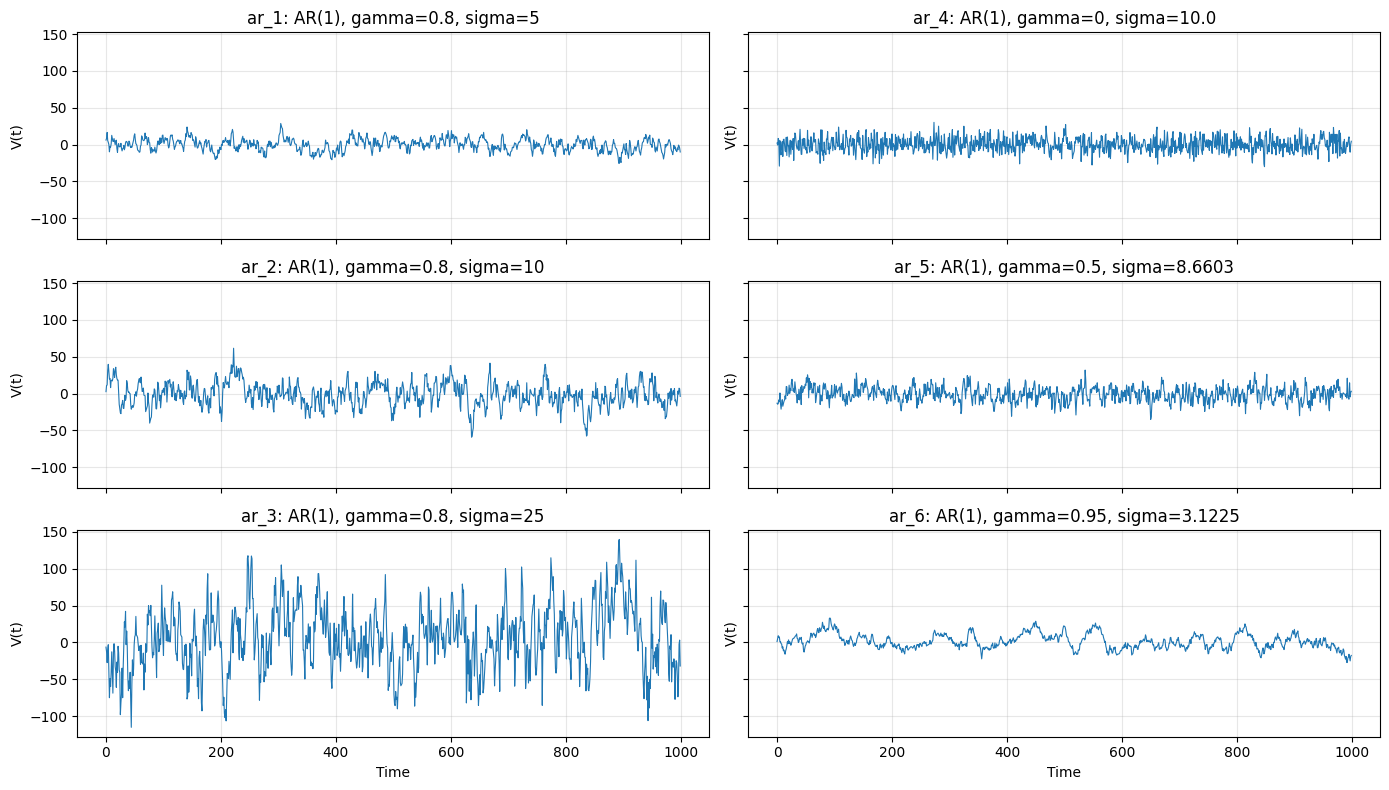

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(14, 8), sharex=True, sharey=True)

# Left column: vary sigma; right column: vary gamma
for ax, s in zip(axes.T.flatten(), ar_series):
    ax.plot(s["data"], linewidth=0.8)
    ax.set_title(f"{s['Series']}: AR(1), gamma={s['Gamma']}, sigma={s['Sigma']}")
    ax.set_ylabel("V(t)")
    ax.grid(alpha=0.3)

for ax in axes[-1]:
    ax.set_xlabel("Time")
plt.tight_layout()
plt.show()

### 2.3 Calculate Sample Entropy

In [8]:
m = 2
tau = 1

sampen_results = []

for s in ar_series:
    ar = s["data"]
    r = 0.2 * np.std(ar) # tolerance relative to each series' std

    samp, A, B = EH.SampEn(
        ar,
        m=m,
        tau=tau,
        r=r,
        Logx=np.e
    )

    sampen_results.append({
        "Series": s["Series"],
        "Experiment": s["Experiment"],
        "Gamma": s["Gamma"],
        "Sigma": s["Sigma"],
        "Std": round(ar.std(), 4),
        "r": round(r, 4),
        "Sample Entropy": round(samp[-1], 4) # samp[-1] is SampEn at embedding dimension m
    })

sampen_df = pd.DataFrame(sampen_results)
sampen_df

,Series,Experiment,Gamma,Sigma,Std,r,Sample Entropy
0,ar_1,Vary sigma,0.80,5.0000,8.3247,1.6649,1.6991
1,ar_2,Vary sigma,0.80,10.0000,16.2324,3.2465,1.6861
2,ar_3,Vary sigma,0.80,25.0000,42.1787,8.4357,1.7050
3,ar_4,Vary gamma,0.00,10.0000,10.0000,2.0000,2.1459
4,ar_5,Vary gamma,0.50,8.6603,10.0000,2.0000,2.0590
5,ar_6,Vary gamma,0.95,3.1225,10.0000,2.0000,1.1509


Text(0.5, 1.0, 'Sample Entropy of Simulated AR(1) Series')

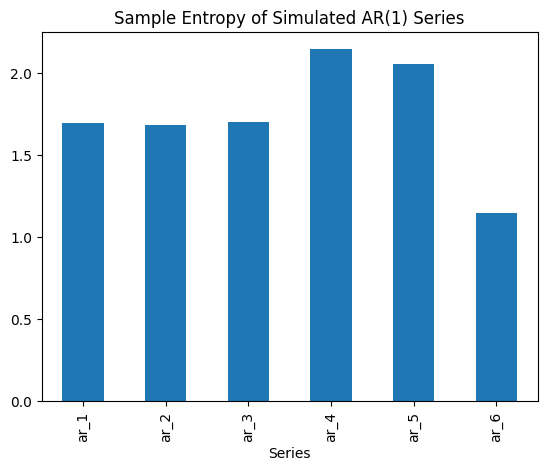

In [9]:
sampen_df.plot(x="Series", y="Sample Entropy", kind="bar", legend=False)
plt.title("Sample Entropy of Simulated AR(1) Series")

### 2.4 Finding
- Same AR coefficient with different noise variance → almost the same Sample Entropy.
- Same series variance with larger AR coefficient → lower Sample Entropy.

Sample entropy measures the irregularity of the chronological order of a time series. (If the trends of two past time series are very similar, what is the probability that they will continue to be similar in the future?)

Because (r) changes with each series' standard deviation, larger fluctuations also lead to a larger tolerance. As a result, Sample Entropy is not strongly affected by the size of the fluctuations, but instead focuses on how regular the patterns are over time. A larger $\gamma$ makes each value depend more on the previous one, so the series is smoother and more predictable, and SampEn decreases.

## 3. Permutation Entropy

$$
H_{\mathrm{perm}}=-\sum_{\pi}p(\pi)\log p(\pi)
$$

where $p(\pi)$ is not the probability of a generation value, but the relative frequency of the ordinal pattern $\pi$ (the rank ordering of consecutive values) in the time series. 

Permutation entropy measures the **complexity of ordinal dynamics**: how diverse the up/down patterns are.

### 3.1 Use the same simulated time series

Reuse the six AR(1) time series from Section 2.1 (vary sigma / vary gamma), so that Permutation Entropy can be compared directly with Sample Entropy.

### 3.2 Calculate Permutation Entropy

In [10]:
m = 4
tau = 1
H_max = np.log2(scipy.special.factorial(m)) # maximum PE = log2(m!), all m! patterns equally likely

permen_results = []

for s in ar_series:
    x = s["data"]
    perm, _, _ = EH.PermEn(
        x,
        m=m,
        tau=tau,
        Logx=2
    )

    permen_results.append({
        "Series": s["Series"],
        "Experiment": s["Experiment"],
        "Gamma": s["Gamma"],
        "Sigma": s["Sigma"],
        "Std": round(x.std(), 4),
        "Permutation Entropy": round(perm[-1], 4), # perm[-1] is PE at embedding dimension m
        "Normalized Permutation Entropy": round(perm[-1] / H_max, 4) # scaled to [0, 1]
    })

permen_df = pd.DataFrame(permen_results)
permen_df

,Series,Experiment,Gamma,Sigma,Std,Permutation Entropy,Normalized Permutation Entropy
0,ar_1,Vary sigma,0.80,5.0000,8.3247,4.3170,0.9416
1,ar_2,Vary sigma,0.80,10.0000,16.2324,4.3968,0.9590
2,ar_3,Vary sigma,0.80,25.0000,42.1787,4.3419,0.9470
3,ar_4,Vary gamma,0.00,10.0000,10.0000,4.5723,0.9972
4,ar_5,Vary gamma,0.50,8.6603,10.0000,4.5275,0.9875
5,ar_6,Vary gamma,0.95,3.1225,10.0000,4.3163,0.9414


Text(0.5, 1.0, 'Permutation Entropy of Simulated AR(1) Series')

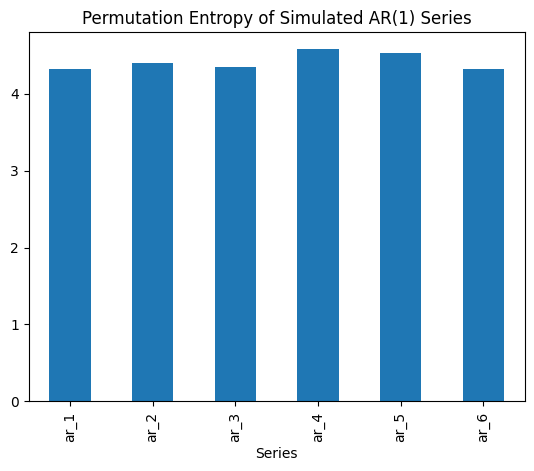

In [11]:
permen_df.plot(x="Series", y="Permutation Entropy", kind="bar", legend=False)
plt.title("Permutation Entropy of Simulated AR(1) Series")

### 3.3 Finding
- Same AR coefficient with different noise variance → almost the same Permutation Entropy.
- Same series variance with larger AR coefficient → lower Permutation Entropy.

Permutation entropy only looks at the rank ordering of consecutive values, not their magnitudes, so it is not affected by the size of the fluctuations. White noise ($\gamma = 0$) produces all ordinal patterns almost equally often, so its normalized PE is close to 1. As $\gamma$ increases, the series has stronger memory and tends to keep rising or falling, so monotonic patterns (e.g. ↑↑↑ or ↓↓↓) appear more often and PE decreases.

## 4. Comparison of Sample Entropy and Permutation Entropy

Both are time-series entropies, so compare them on the same six AR(1) time series from Section 2.1:

- **Vary sigma** (`ar_1`–`ar_3`): same $\gamma = 0.8$, different $\sigma = 5, 10, 25$.
- **Vary gamma** (`ar_4`–`ar_6`): same std = 10, different $\gamma = 0, 0.5, 0.95$.

### 4.1 Compare Sample Entropy and Permutation Entropy

In [12]:
compare_df = sampen_df[["Series", "Experiment", "Gamma", "Sigma", "Std", "Sample Entropy"]].merge(
    permen_df[["Series", "Normalized Permutation Entropy"]], on="Series"
)
compare_df

,Series,Experiment,Gamma,Sigma,Std,Sample Entropy,Normalized Permutation Entropy
0,ar_1,Vary sigma,0.80,5.0000,8.3247,1.6991,0.9416
1,ar_2,Vary sigma,0.80,10.0000,16.2324,1.6861,0.9590
2,ar_3,Vary sigma,0.80,25.0000,42.1787,1.7050,0.9470
3,ar_4,Vary gamma,0.00,10.0000,10.0000,2.1459,0.9972
4,ar_5,Vary gamma,0.50,8.6603,10.0000,2.0590,0.9875
5,ar_6,Vary gamma,0.95,3.1225,10.0000,1.1509,0.9414


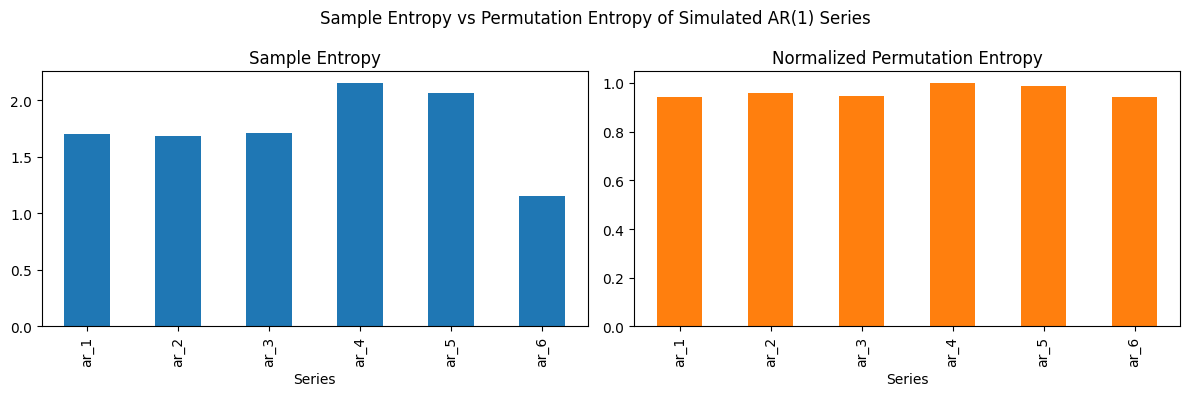

In [13]:
compare_df.plot(x="Series", y=["Sample Entropy", "Normalized Permutation Entropy"], kind="bar",
                subplots=True, layout=(1, 2), figsize=(12, 4), legend=False)
plt.suptitle("Sample Entropy vs Permutation Entropy of Simulated AR(1) Series")
plt.tight_layout()

### 4.2 Why does Permutation Entropy change less than Sample Entropy when varying gamma?

Even in relative terms, from $\gamma = 0$ to $0.95$, SampEn drops by about 46% while normalized PE only drops by about 6%. Two reasons:

1. **SampEn uses amplitude, PE only uses ranks.** SampEn checks whether values stay within tolerance $r = 0.2 \cdot \mathrm{std}$. For a stationary AR(1), the one-step change has $\mathrm{std}(V_t - V_{t-1}) = \mathrm{std}(V)\sqrt{2(1-\gamma)}$, so a larger $\gamma$ makes each step much smaller compared with $r$. If two templates match, the next values are then very likely to still match → $A/B$ gets close to 1 → SampEn drops a lot. PE ignores *how much* the series moves and only records *whether* it goes up or down.

2. **PE has a floor for AR(1).** Near $\gamma = 1$, AR(1) behaves like a random walk, whose steps $\varepsilon_t$ are still independent, so the up/down directions are still nearly random and the ordinal patterns are still very diverse. A random walk only has normalized PE ≈ 0.94 (for $m = 4$), so for $0 \le \gamma < 1$ PE can only move within roughly $[0.94, 1]$.

In [14]:
# Reason 1: one-step change size compared with the SampEn tolerance r
why_results = []

for s in ar_series:
    if s["Experiment"] != "Vary gamma":
        continue

    x = s["data"]
    r = 0.2 * np.std(x)
    step_std = np.diff(x).std() # std of V_t - V_{t-1}

    why_results.append({
        "Series": s["Series"],
        "Gamma": s["Gamma"],
        "r": round(r, 4),
        "Step std": round(step_std, 4),
        "Step std / r": round(step_std / r, 4)
    })

why_df = pd.DataFrame(why_results).merge(compare_df[["Series", "Sample Entropy", "Normalized Permutation Entropy"]], on="Series")
why_df

,Series,Gamma,r,Step std,Step std / r,Sample Entropy,Normalized Permutation Entropy
0,ar_4,0.00,2.0,14.1867,7.0933,2.1459,0.9972
1,ar_5,0.50,2.0,10.1555,5.0777,2.0590,0.9875
2,ar_6,0.95,2.0,3.4082,1.7041,1.1509,0.9414


In [15]:
# Reason 2: random walk (gamma = 1) gives the lower limit of PE for AR(1)
random_walk = np.cumsum(rng.normal(loc=0, scale=1, size=100000)) # long series for a stable estimate
perm, _, _ = EH.PermEn(random_walk, m=m, tau=tau, Logx=2)

print(f"Normalized PE of random walk (m={m}): {perm[-1] / H_max:.4f}")

Normalized PE of random walk (m=4): 0.9375


### 4.3 Finding

| | Vary sigma (same $\gamma$) | Vary gamma (same std) |
|---|---|---|
| Sample Entropy | almost the same | decreases with $\gamma$ |
| Permutation Entropy | almost the same | decreases with $\gamma$ (only slightly) |

Both Sample Entropy and Permutation Entropy respond to temporal structure ($\gamma$) rather than amplitude ($\sigma$).

Sample Entropy is more sensitive to $\gamma$, because it uses the size of the changes (compared with $r$), while Permutation Entropy only uses the rank ordering of values and is bounded below by the random-walk level (≈ 0.94).